# Day 4 · Regularization & Model Evaluation
Manual L2 added to the Day 2 gradient-descent model, tuned with `GridSearchCV` on **noisy weather data**.

Setup: a small sample (200 rows), Gaussian noise added to the weather features, and degree-3 polynomial expansion, so the model can overfit and α actually matters.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv("crop_yield.csv")          # put crop_yield.csv next to this notebook
print(df.shape)
df.head()

(1000000, 10)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [2]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

NUM = ["Rainfall_mm", "Temperature_Celsius", "Fertilizer_Used", "Irrigation_Used", "Days_to_Harvest"]
rng = np.random.default_rng(42)
sub = df.sample(200, random_state=42)
X = sub[NUM].astype(float).to_numpy(); y = sub["Yield_tons_per_hectare"].to_numpy()

# noisy weather data: add noise to rainfall and temperature (100% of each column's std)
for j in (0, 1):
    X[:, j] += rng.normal(0, 1.0 * X[:, j].std(), len(X))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
poly = PolynomialFeatures(3, include_bias=False).fit(X_tr)
sc = StandardScaler().fit(poly.transform(X_tr))
Xtr, Xte = sc.transform(poly.transform(X_tr)), sc.transform(poly.transform(X_te))
print("features after poly expansion:", Xtr.shape[1])

features after poly expansion: 55


The Day 2 model with an L2 penalty: loss = MSE + α·‖w‖² (bias not penalised), wrapped as an sklearn estimator so `GridSearchCV` can tune it.

In [3]:
class ManualRidge(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=0.0, lr=0.003, epochs=3000):
        self.alpha, self.lr, self.epochs = alpha, lr, epochs
    def fit(self, X, y):
        n, d = X.shape; self.w_ = np.zeros(d); self.b_ = 0.0; self.history_ = []
        for _ in range(self.epochs):
            err = X @ self.w_ + self.b_ - y
            self.w_ -= self.lr * ((2 / n) * X.T @ err + 2 * self.alpha * self.w_)   # L2 term
            self.b_ -= self.lr * (2 / n) * err.sum()
            self.history_.append((err ** 2).mean() + self.alpha * (self.w_ ** 2).sum())
        return self
    def predict(self, X): return X @ self.w_ + self.b_

alphas = [0, 0.001, 0.01, 0.1, 0.3, 1, 3, 10]
gs = GridSearchCV(ManualRidge(), {"alpha": alphas}, cv=5, scoring="neg_mean_squared_error", return_train_score=True)
gs.fit(Xtr, y_tr)
res = pd.DataFrame(gs.cv_results_)[["param_alpha", "mean_train_score", "mean_test_score"]]
res[["mean_train_score", "mean_test_score"]] *= -1
res.columns = ["alpha", "train MSE (cv)", "val MSE (cv)"]
print("best alpha:", gs.best_params_)
res

best alpha: {'alpha': 0.1}


,alpha,train MSE (cv),val MSE (cv)
0,0.000,0.902520,1.235775
1,0.001,0.902871,1.234998
2,0.010,0.906137,1.228724
3,0.100,0.940109,1.203757
4,0.300,0.991462,1.203924
5,1.000,1.063575,1.220720
6,3.000,1.150964,1.254842
7,10.000,1.396558,1.453516


held-out test MSE   alpha=0: 1.1005   best alpha=0.1: 1.1088


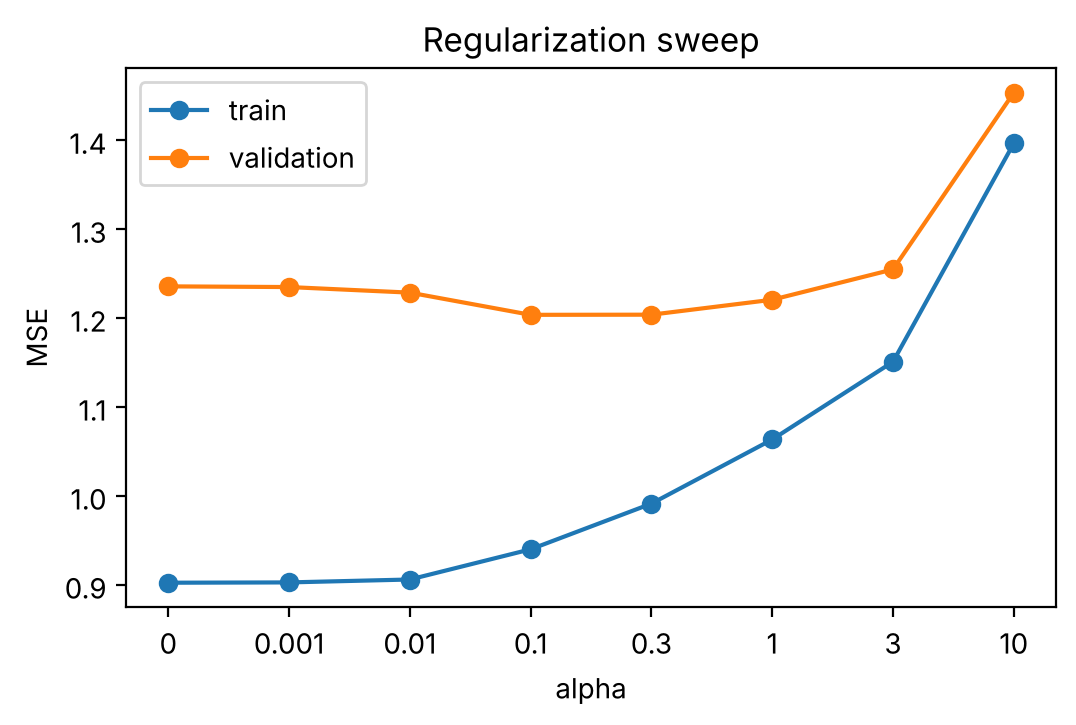

In [4]:
no_reg = ManualRidge(alpha=0).fit(Xtr, y_tr)
mse = lambda m: ((m.predict(Xte) - y_te) ** 2).mean()
print(f"held-out test MSE   alpha=0: {mse(no_reg):.4f}   best alpha={gs.best_params_['alpha']}: {mse(gs.best_estimator_):.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(range(len(alphas)), res["train MSE (cv)"], "o-", label="train")
plt.plot(range(len(alphas)), res["val MSE (cv)"], "o-", label="validation")
plt.xticks(range(len(alphas)), alphas); plt.xlabel("alpha"); plt.ylabel("MSE"); plt.legend(); plt.title("Regularization sweep"); plt.show()